## Importando Bibliotecas e Carregando os Dados

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

In [2]:
sns.set_theme(style="whitegrid")
caminho_atual = Path(".").resolve()
pasta_dados = caminho_atual.parent / "data"
pasta_reports = caminho_atual / "reports"
pasta_reports.mkdir(parents=True, exist_ok=True)

df_train = pd.read_csv(pasta_dados / "processed" / "train_processed.csv")
df_test = pd.read_csv(pasta_dados / "processed" / "test_processed.csv")

df_train_scaled = pd.read_csv(pasta_dados / "processed" / "train_scaled.csv")
df_test_scaled = pd.read_csv(pasta_dados / "processed" / "test_scaled.csv")
df_test_raw = pd.read_csv(pasta_dados / "raw" / "test.csv")

X = df_train.drop(columns=["Survived"])
y = df_train["Survived"]
X_scaled = df_train_scaled.drop(columns=["Survived"])

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr_sc, X_val_sc, _, _ = train_test_split(X_scaled, y, test_size=0.20, random_state=42, stratify=y)

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Treino: {X_tr.shape} | Validação: {X_val.shape} | Relatórios em: {pasta_reports}")

Treino: (569, 26) | Validação: (143, 26) | Relatórios em: C:\vscode\github\titanic_analysis\notebooks\reports


## 1. Random Forest: Impacto de Cada Hiperparâmetro

Testamos individualmente a variação de `max_depth`, `n_estimators` e `min_samples_leaf` para visualizar o efeito real nas métricas de validação e validação cruzada.

In [3]:
valores_depth_rf = [3, 4, 6, 8, 10, 12, 15, None]
lista_rf_depth = []

for d in valores_depth_rf:
    rf = RandomForestClassifier(n_estimators=200, max_depth=d, random_state=42)
    rf.fit(X_tr, y_tr)
    y_p = rf.predict(X_val)
    y_prob = rf.predict_proba(X_val)[:, 1]
    cv_acc = cross_val_score(rf, X, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(rf, X, y, cv=kfold, scoring="f1").mean()
    
    lista_rf_depth.append({
        "max_depth": str(d),
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val Precision": round(precision_score(y_val, y_p), 4),
        "Val Recall": round(recall_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_rf_depth = pd.DataFrame(lista_rf_depth)
print("Resultados Random Forest variando max_depth:")
display(df_rf_depth)

Resultados Random Forest variando max_depth:


,max_depth,CV Accuracy,CV F1,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,3,0.8244,0.7571,0.8252,0.7885,0.7455,0.7664,0.8968
1,4,0.8300,0.7664,0.8462,0.8113,0.7818,0.7963,0.9018
2,6,0.8357,0.7749,0.8322,0.7925,0.7636,0.7778,0.9064
3,8,0.8371,0.7784,0.8392,0.8077,0.7636,0.7850,0.8981
4,10,0.8301,0.7685,0.8322,0.7925,0.7636,0.7778,0.8979
5,12,0.8244,0.7634,0.8392,0.8077,0.7636,0.7850,0.8899
6,15,0.8118,0.7507,0.8252,0.7778,0.7636,0.7706,0.8913
7,None,0.8034,0.7412,0.8392,0.7759,0.8182,0.7965,0.8930


In [4]:
valores_est_rf = [50, 100, 150, 200, 300, 500]
lista_rf_est = []

for n in valores_est_rf:
    rf = RandomForestClassifier(n_estimators=n, max_depth=10, random_state=42)
    rf.fit(X_tr, y_tr)
    y_p = rf.predict(X_val)
    y_prob = rf.predict_proba(X_val)[:, 1]
    cv_acc = cross_val_score(rf, X, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(rf, X, y, cv=kfold, scoring="f1").mean()
    
    lista_rf_est.append({
        "n_estimators": n,
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_rf_est = pd.DataFrame(lista_rf_est)
print("Resultados Random Forest variando n_estimators (com max_depth=10):")
display(df_rf_est)

valores_leaf_rf = [1, 2, 3, 4, 5, 8]
lista_rf_leaf = []

for leaf in valores_leaf_rf:
    rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=leaf, random_state=42)
    rf.fit(X_tr, y_tr)
    y_p = rf.predict(X_val)
    y_prob = rf.predict_proba(X_val)[:, 1]
    cv_acc = cross_val_score(rf, X, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(rf, X, y, cv=kfold, scoring="f1").mean()
    
    lista_rf_leaf.append({
        "min_samples_leaf": leaf,
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_rf_leaf = pd.DataFrame(lista_rf_leaf)
print("\nResultados Random Forest variando min_samples_leaf (com max_depth=10):")
display(df_rf_leaf)

Resultados Random Forest variando n_estimators (com max_depth=10):


,n_estimators,CV Accuracy,CV F1,Val Accuracy,Val F1,Val ROC-AUC
0,50,0.8300,0.7693,0.8252,0.7706,0.8912
1,100,0.8301,0.7711,0.8322,0.7778,0.8925
2,150,0.8342,0.7731,0.8322,0.7778,0.8964
3,200,0.8301,0.7685,0.8322,0.7778,0.8979
4,300,0.8343,0.7751,0.8392,0.7850,0.9002
5,500,0.8370,0.7781,0.8462,0.7925,0.8998



Resultados Random Forest variando min_samples_leaf (com max_depth=10):


,min_samples_leaf,CV Accuracy,CV F1,Val Accuracy,Val F1,Val ROC-AUC
0,1,0.8301,0.7685,0.8322,0.7778,0.8979
1,2,0.8357,0.7760,0.8322,0.7778,0.9021
2,3,0.8357,0.7739,0.8252,0.7706,0.9045
3,4,0.8315,0.7694,0.8182,0.7593,0.9017
4,5,0.8287,0.7650,0.8112,0.7523,0.9037
5,8,0.8300,0.7646,0.8182,0.7547,0.9035


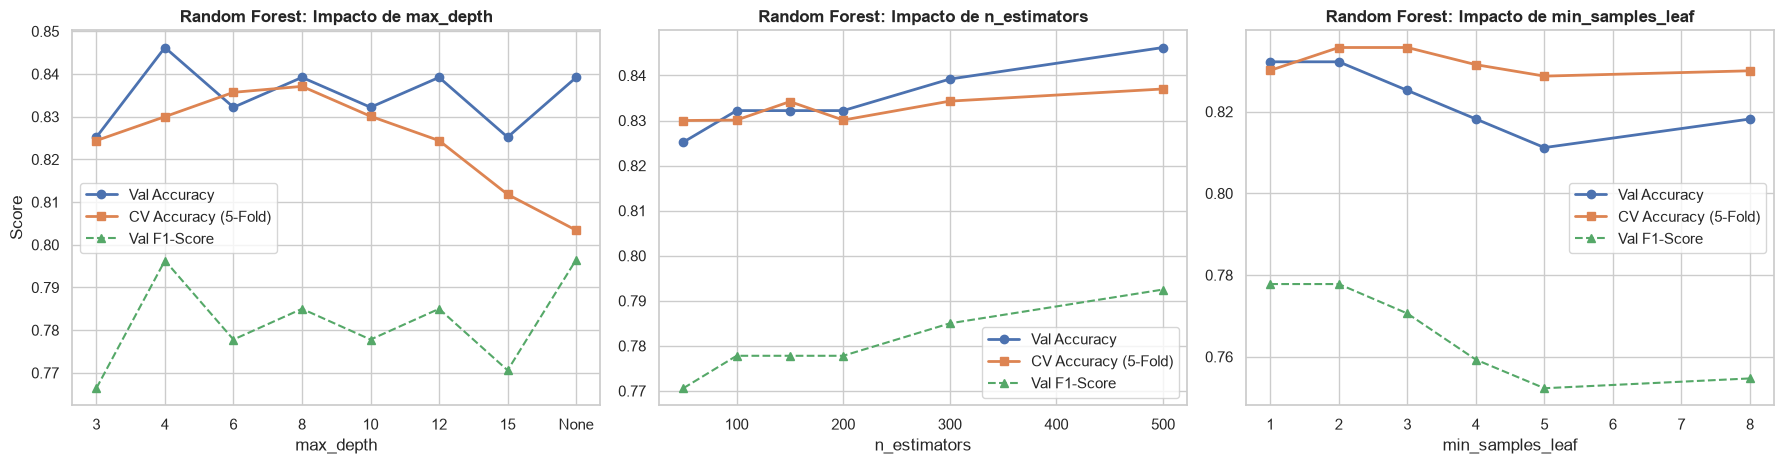

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(df_rf_depth["max_depth"], df_rf_depth["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
axes[0].plot(df_rf_depth["max_depth"], df_rf_depth["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
axes[0].plot(df_rf_depth["max_depth"], df_rf_depth["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
axes[0].set_title("Random Forest: Impacto de max_depth", fontweight="bold")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("Score")
axes[0].legend()

axes[1].plot(df_rf_est["n_estimators"], df_rf_est["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
axes[1].plot(df_rf_est["n_estimators"], df_rf_est["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
axes[1].plot(df_rf_est["n_estimators"], df_rf_est["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
axes[1].set_title("Random Forest: Impacto de n_estimators", fontweight="bold")
axes[1].set_xlabel("n_estimators")
axes[1].legend()

axes[2].plot(df_rf_leaf["min_samples_leaf"], df_rf_leaf["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
axes[2].plot(df_rf_leaf["min_samples_leaf"], df_rf_leaf["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
axes[2].plot(df_rf_leaf["min_samples_leaf"], df_rf_leaf["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
axes[2].set_title("Random Forest: Impacto de min_samples_leaf", fontweight="bold")
axes[2].set_xlabel("min_samples_leaf")
axes[2].legend()

plt.tight_layout()
plt.savefig(pasta_reports / "rf_parametros.png", dpi=150)
plt.show()

## 2. XGBoost: Impacto de Cada Hiperparâmetro

Analisamos como `max_depth`, `learning_rate` e `n_estimators` alteram o resultado do **XGBoost**.

In [6]:
valores_depth_xgb = [2, 3, 4, 5, 6, 8, 10]
lista_xgb_depth = []

for d in valores_depth_xgb:
    xgb = XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=d, random_state=42, eval_metric="logloss")
    xgb.fit(X_tr, y_tr)
    y_p = xgb.predict(X_val)
    y_prob = xgb.predict_proba(X_val)[:, 1]
    cv_acc = cross_val_score(xgb, X, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(xgb, X, y, cv=kfold, scoring="f1").mean()
    
    lista_xgb_depth.append({
        "max_depth": d,
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val Precision": round(precision_score(y_val, y_p), 4),
        "Val Recall": round(recall_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_xgb_depth = pd.DataFrame(lista_xgb_depth)
print("Resultados XGBoost variando max_depth:")
display(df_xgb_depth)

valores_lr_xgb = [0.01, 0.03, 0.05, 0.08, 0.1, 0.2]
lista_xgb_lr = []

for lr in valores_lr_xgb:
    xgb = XGBClassifier(n_estimators=150, learning_rate=lr, max_depth=4, random_state=42, eval_metric="logloss")
    xgb.fit(X_tr, y_tr)
    y_p = xgb.predict(X_val)
    y_prob = xgb.predict_proba(X_val)[:, 1]
    cv_acc = cross_val_score(xgb, X, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(xgb, X, y, cv=kfold, scoring="f1").mean()
    
    lista_xgb_lr.append({
        "learning_rate": lr,
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_xgb_lr = pd.DataFrame(lista_xgb_lr)
print("\nResultados XGBoost variando learning_rate:")
display(df_xgb_lr)

valores_est_xgb = [50, 100, 150, 200, 300, 400]
lista_xgb_est = []

for n in valores_est_xgb:
    xgb = XGBClassifier(n_estimators=n, learning_rate=0.05, max_depth=4, random_state=42, eval_metric="logloss")
    xgb.fit(X_tr, y_tr)
    y_p = xgb.predict(X_val)
    y_prob = xgb.predict_proba(X_val)[:, 1]
    cv_acc = cross_val_score(xgb, X, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(xgb, X, y, cv=kfold, scoring="f1").mean()
    
    lista_xgb_est.append({
        "n_estimators": n,
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_xgb_est = pd.DataFrame(lista_xgb_est)
print("\nResultados XGBoost variando n_estimators:")
display(df_xgb_est)

Resultados XGBoost variando max_depth:


,max_depth,CV Accuracy,CV F1,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,2,0.8273,0.7603,0.8042,0.7647,0.7091,0.7358,0.8969
1,3,0.8343,0.7700,0.8042,0.7455,0.7455,0.7455,0.8970
2,4,0.8357,0.7762,0.7902,0.7193,0.7455,0.7321,0.8925
3,5,0.8272,0.7654,0.8042,0.7368,0.7636,0.7500,0.8864
4,6,0.8286,0.7700,0.8182,0.7636,0.7636,0.7636,0.8835
5,8,0.8230,0.7626,0.8182,0.7636,0.7636,0.7636,0.8849
6,10,0.8244,0.7640,0.8182,0.7636,0.7636,0.7636,0.8855



Resultados XGBoost variando learning_rate:


,learning_rate,CV Accuracy,CV F1,Val Accuracy,Val F1,Val ROC-AUC
0,0.01,0.8329,0.7662,0.8392,0.7810,0.9002
1,0.03,0.8371,0.7752,0.7902,0.7273,0.8955
2,0.05,0.8357,0.7762,0.7902,0.7321,0.8925
3,0.08,0.8357,0.7781,0.7972,0.7387,0.8982
4,0.10,0.8216,0.7605,0.8252,0.7706,0.8964
5,0.20,0.8188,0.7550,0.8042,0.7544,0.8905



Resultados XGBoost variando n_estimators:


,n_estimators,CV Accuracy,CV F1,Val Accuracy,Val F1,Val ROC-AUC
0,50,0.8357,0.7708,0.8182,0.7593,0.8964
1,100,0.8385,0.7779,0.7832,0.7207,0.8907
2,150,0.8357,0.7762,0.7902,0.7321,0.8925
3,200,0.8342,0.7752,0.7972,0.7387,0.8894
4,300,0.8300,0.7704,0.8042,0.7500,0.8939
5,400,0.8230,0.7613,0.8112,0.7568,0.8883


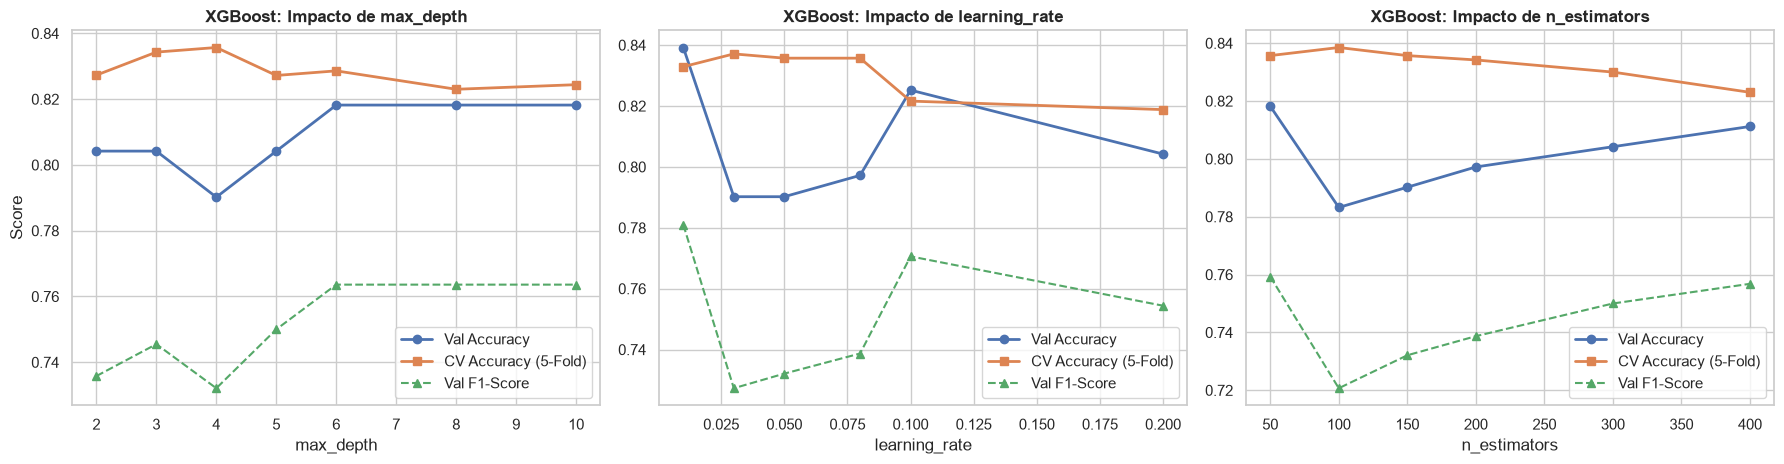

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(df_xgb_depth["max_depth"], df_xgb_depth["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
axes[0].plot(df_xgb_depth["max_depth"], df_xgb_depth["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
axes[0].plot(df_xgb_depth["max_depth"], df_xgb_depth["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
axes[0].set_title("XGBoost: Impacto de max_depth", fontweight="bold")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("Score")
axes[0].legend()

axes[1].plot(df_xgb_lr["learning_rate"], df_xgb_lr["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
axes[1].plot(df_xgb_lr["learning_rate"], df_xgb_lr["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
axes[1].plot(df_xgb_lr["learning_rate"], df_xgb_lr["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
axes[1].set_title("XGBoost: Impacto de learning_rate", fontweight="bold")
axes[1].set_xlabel("learning_rate")
axes[1].legend()

axes[2].plot(df_xgb_est["n_estimators"], df_xgb_est["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
axes[2].plot(df_xgb_est["n_estimators"], df_xgb_est["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
axes[2].plot(df_xgb_est["n_estimators"], df_xgb_est["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
axes[2].set_title("XGBoost: Impacto de n_estimators", fontweight="bold")
axes[2].set_xlabel("n_estimators")
axes[2].legend()

plt.tight_layout()
plt.savefig(pasta_reports / "xgb_parametros.png", dpi=150)
plt.show()

## 3. Logistic Regression: Impacto da Regularização (`C`)

Testamos diferentes forças de regularização (`C`) nos dados padronizados.

Resultados Logistic Regression variando C:


,C,CV Accuracy,CV F1,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,0.01,0.7725,0.6247,0.7622,0.7561,0.5636,0.6458,0.8593
1,0.05,0.8216,0.7610,0.8042,0.7455,0.7455,0.7455,0.8671
2,0.1,0.8244,0.7663,0.8112,0.7500,0.7636,0.7568,0.8651
3,0.25,0.8272,0.7696,0.8182,0.7544,0.7818,0.7679,0.8651
4,0.5,0.8315,0.7770,0.8182,0.7544,0.7818,0.7679,0.8636
5,1.0,0.8273,0.7717,0.8182,0.7544,0.7818,0.7679,0.8630
6,2.0,0.8244,0.7685,0.8252,0.7679,0.7818,0.7748,0.8632
7,5.0,0.8230,0.7663,0.8182,0.7636,0.7636,0.7636,0.8626
8,10.0,0.8202,0.7636,0.8182,0.7636,0.7636,0.7636,0.8605


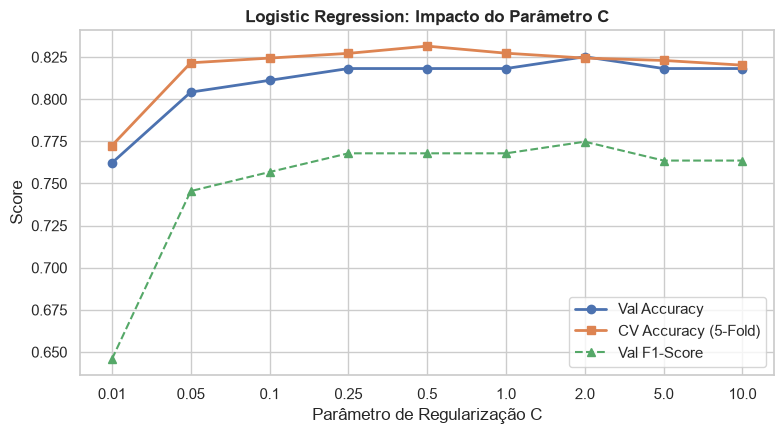

In [8]:
valores_c = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]
lista_lr_c = []

for c in valores_c:
    lr_mod = LogisticRegression(C=c, max_iter=1000, random_state=42)
    lr_mod.fit(X_tr_sc, y_tr)
    y_p = lr_mod.predict(X_val_sc)
    y_prob = lr_mod.predict_proba(X_val_sc)[:, 1]
    cv_acc = cross_val_score(lr_mod, X_scaled, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(lr_mod, X_scaled, y, cv=kfold, scoring="f1").mean()
    
    lista_lr_c.append({
        "C": str(c),
        "CV Accuracy": round(cv_acc, 4),
        "CV F1": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val Precision": round(precision_score(y_val, y_p), 4),
        "Val Recall": round(recall_score(y_val, y_p), 4),
        "Val F1": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_lr_c = pd.DataFrame(lista_lr_c)
print("Resultados Logistic Regression variando C:")
display(df_lr_c)

plt.figure(figsize=(8, 4.5))
plt.plot(df_lr_c["C"], df_lr_c["Val Accuracy"], marker="o", label="Val Accuracy", linewidth=2)
plt.plot(df_lr_c["C"], df_lr_c["CV Accuracy"], marker="s", label="CV Accuracy (5-Fold)", linewidth=2)
plt.plot(df_lr_c["C"], df_lr_c["Val F1"], marker="^", label="Val F1-Score", linestyle="--")
plt.title("Logistic Regression: Impacto do Parâmetro C", fontweight="bold")
plt.xlabel("Parâmetro de Regularização C")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.savefig(pasta_reports / "lr_parametros.png", dpi=150)
plt.show()

## 4. Otimização Combinada com `GridSearchCV`

Utilizamos o `GridSearchCV` com validação cruzada estratificada de 5 folds para encontrar a melhor combinação conjunta de hiperparâmetros para **Random Forest**, **XGBoost** e **Logistic Regression**.

In [9]:
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [6, 8, 10, 12],
    "min_samples_leaf": [1, 2, 3],
    "min_samples_split": [2, 5]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=kfold,
    scoring="accuracy",
    n_jobs=1
)
grid_rf.fit(X, y)

print("Melhores parâmetros Random Forest:", grid_rf.best_params_)
print(f"Melhor CV Accuracy: {grid_rf.best_score_:.4f}")

cols_rf_grid = ["param_max_depth", "param_n_estimators", "param_min_samples_leaf", "param_min_samples_split", "mean_test_score", "std_test_score"]
top_rf_grid = pd.DataFrame(grid_rf.cv_results_)[cols_rf_grid].sort_values(by="mean_test_score", ascending=False).head(5)
display(top_rf_grid)

Melhores parâmetros Random Forest: {'max_depth': 12, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
Melhor CV Accuracy: 0.8427


,param_max_depth,param_n_estimators,param_min_samples_leaf,param_min_samples_split,mean_test_score,std_test_score
65,12,300,2,5,0.842687,0.015250
61,12,200,2,2,0.842677,0.014692
41,10,300,1,5,0.841278,0.014627
60,12,100,2,2,0.839890,0.011175
59,12,300,1,5,0.839880,0.013712


In [10]:
param_grid_xgb = {
    "n_estimators": [100, 150, 250],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric="logloss"),
    param_grid=param_grid_xgb,
    cv=kfold,
    scoring="accuracy",
    n_jobs=1
)
grid_xgb.fit(X, y)

print("Melhores parâmetros XGBoost:", grid_xgb.best_params_)
print(f"Melhor CV Accuracy: {grid_xgb.best_score_:.4f}")

cols_xgb_grid = ["param_max_depth", "param_learning_rate", "param_n_estimators", "param_subsample", "param_colsample_bytree", "mean_test_score"]
top_xgb_grid = pd.DataFrame(grid_xgb.cv_results_)[cols_xgb_grid].sort_values(by="mean_test_score", ascending=False).head(5)
display(top_xgb_grid)

Melhores parâmetros XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 8, 'n_estimators': 100, 'subsample': 0.8}
Melhor CV Accuracy: 0.8455


,param_max_depth,param_learning_rate,param_n_estimators,param_subsample,param_colsample_bytree,mean_test_score
18,8,0.03,100,0.8,0.8,0.845504
42,8,0.05,100,0.8,0.8,0.844095
32,4,0.05,150,0.8,0.8,0.842687
52,3,0.10,250,0.8,0.8,0.842677
12,6,0.03,100,0.8,0.8,0.841298


In [11]:
param_grid_lr = {
    "C": [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0],
    "solver": ["lbfgs", "liblinear"]
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid=param_grid_lr,
    cv=kfold,
    scoring="accuracy",
    n_jobs=1
)
grid_lr.fit(X_scaled, y)

print("Melhores parâmetros Logistic Regression:", grid_lr.best_params_)
print(f"Melhor CV Accuracy: {grid_lr.best_score_:.4f}")

cols_lr_grid = ["param_C", "param_solver", "mean_test_score", "std_test_score"]
top_lr_grid = pd.DataFrame(grid_lr.cv_results_)[cols_lr_grid].sort_values(by="mean_test_score", ascending=False).head(5)
display(top_lr_grid)

Melhores parâmetros Logistic Regression: {'C': 0.5, 'solver': 'liblinear'}
Melhor CV Accuracy: 0.8329


,param_C,param_solver,mean_test_score,std_test_score
7,0.50,liblinear,0.832867,0.011211
6,0.50,lbfgs,0.831478,0.011490
9,1.00,liblinear,0.828652,0.013025
8,1.00,lbfgs,0.827263,0.009230
4,0.25,lbfgs,0.827243,0.015823


## 5. Comparativo Real: Baseline vs Modelos Tunados

Comparamos lado a lado as versões iniciais (Baseline do `03_modeling.ipynb`) contra as versões otimizadas.

In [12]:
modelos_comparacao = {
    "RF Baseline (depth=6)": RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=3, random_state=42),
    "RF (depth=10)": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=1, random_state=42),
    "RF GridSearch": RandomForestClassifier(**grid_rf.best_params_, random_state=42),
    "XGB Baseline (depth=3)": XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42, eval_metric="logloss"),
    "XGB GridSearch": XGBClassifier(**grid_xgb.best_params_, random_state=42, eval_metric="logloss"),
    "LR Baseline (C=1.0)": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "LR GridSearch": LogisticRegression(**grid_lr.best_params_, max_iter=1000, random_state=42)
}

tabela_final = []
preds_finais = {}
probs_finais = {}

for nome, mod in modelos_comparacao.items():
    if nome.startswith("LR"):
        x_t, x_v, x_all = X_tr_sc, X_val_sc, X_scaled
    else:
        x_t, x_v, x_all = X_tr, X_val, X

    mod.fit(x_t, y_tr)
    y_p = mod.predict(x_v)
    y_pr = mod.predict_proba(x_v)[:, 1]
    preds_finais[nome] = y_p
    probs_finais[nome] = y_pr

    cv_acc = cross_val_score(mod, x_all, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(mod, x_all, y, cv=kfold, scoring="f1").mean()

    tabela_final.append({
        "Modelo": nome,
        "CV Accuracy": round(cv_acc, 4),
        "CV F1-Score": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_p), 4),
        "Val Precision": round(precision_score(y_val, y_p), 4),
        "Val Recall": round(recall_score(y_val, y_p), 4),
        "Val F1-Score": round(f1_score(y_val, y_p), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_pr), 4)
    })

df_comparacao = pd.DataFrame(tabela_final).sort_values(by=["Val Accuracy", "CV Accuracy"], ascending=False)
display(df_comparacao)

,Modelo,CV Accuracy,CV F1-Score,Val Accuracy,Val Precision,Val Recall,Val F1-Score,Val ROC-AUC
4,XGB GridSearch,0.8455,0.7879,0.8462,0.8235,0.7636,0.7925,0.9056
2,RF GridSearch,0.8427,0.7847,0.8322,0.7925,0.7636,0.7778,0.8992
1,RF (depth=10),0.8301,0.7685,0.8322,0.7925,0.7636,0.7778,0.8979
6,LR GridSearch,0.8329,0.7777,0.8182,0.7544,0.7818,0.7679,0.8674
0,RF Baseline (depth=6),0.8301,0.7664,0.8182,0.7636,0.7636,0.7636,0.9012
5,LR Baseline (C=1.0),0.8273,0.7717,0.8182,0.7544,0.7818,0.7679,0.8630
3,XGB Baseline (depth=3),0.8343,0.7700,0.8042,0.7455,0.7455,0.7455,0.8970


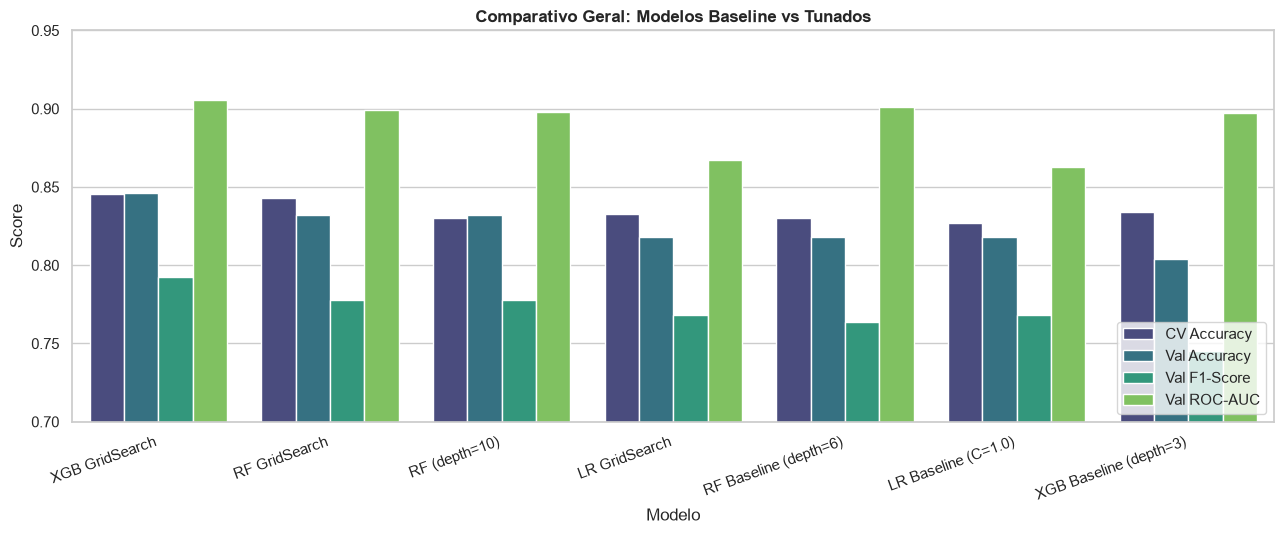

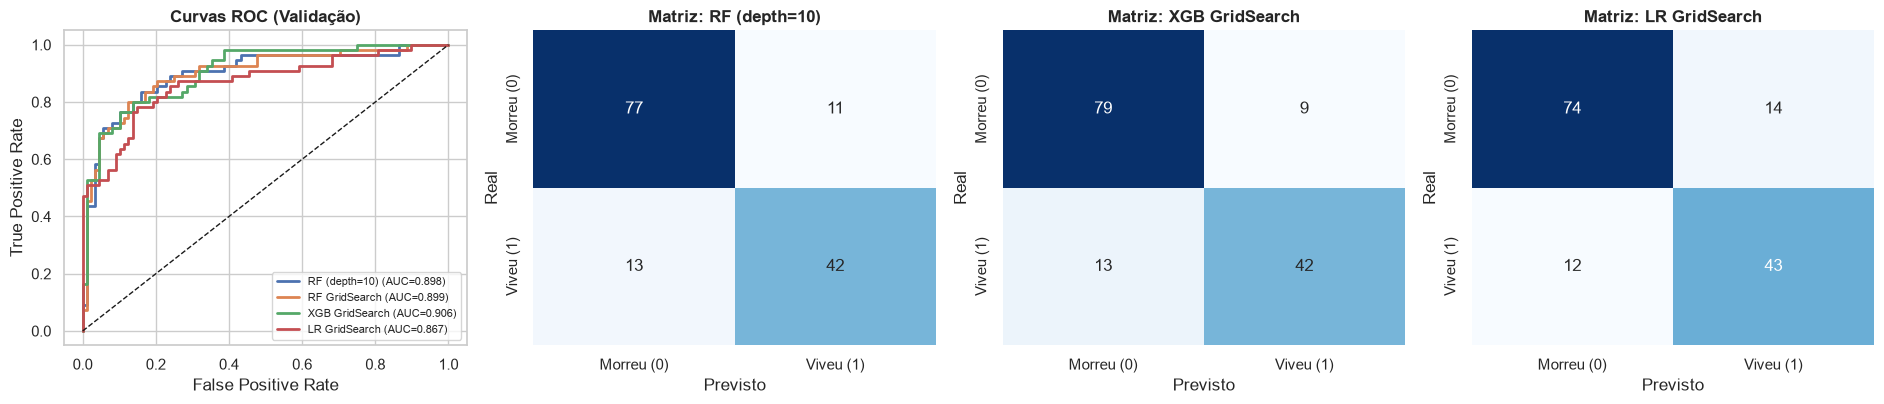

In [13]:
# Gráfico 1: Comparação de Barras (Baseline vs Tunado)
df_melt = df_comparacao.melt(
    id_vars="Modelo",
    value_vars=["CV Accuracy", "Val Accuracy", "Val F1-Score", "Val ROC-AUC"],
    var_name="Métrica",
    value_name="Score"
)

plt.figure(figsize=(13, 5.5))
sns.barplot(data=df_melt, x="Modelo", y="Score", hue="Métrica", palette="viridis")
plt.title("Comparativo Geral: Modelos Baseline vs Tunados", fontweight="bold")
plt.ylim(0.70, 0.95)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(pasta_reports / "comparacao_baseline_vs_tuned.png", dpi=150)
plt.show()

# Gráfico 2: Curvas ROC e Matrizes de Confusão dos Melhores Modelos
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))

modelos_destaque = ["RF (depth=10)", "RF GridSearch", "XGB GridSearch", "LR GridSearch"]
for nome in modelos_destaque:
    fpr, tpr, _ = roc_curve(y_val, probs_finais[nome])
    auc_val = roc_auc_score(y_val, probs_finais[nome])
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{nome} (AUC={auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set_title("Curvas ROC (Validação)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)

for idx, nome in enumerate(["RF (depth=10)", "XGB GridSearch", "LR GridSearch"]):
    cm = confusion_matrix(y_val, preds_finais[nome])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx + 1],
        xticklabels=["Morreu (0)", "Viveu (1)"],
        yticklabels=["Morreu (0)", "Viveu (1)"]
    )
    axes[idx + 1].set_title(f"Matriz: {nome}", fontweight="bold")
    axes[idx + 1].set_xlabel("Previsto")
    axes[idx + 1].set_ylabel("Real")

plt.tight_layout()
plt.savefig(pasta_reports / "roc_e_matrizes_tuned.png", dpi=150)
plt.show()

## 6. Exportação de `metrics.txt` e Atualização do `test_inferred.csv`

In [14]:
linhas_txt = [
    "====================================================================================",
    "RELATORIO DE METRICAS E TUNING DE HIPERPARAMETROS (RF, XGBOOST, LOGISTIC REGRESSION)",
    "====================================================================================\n",
    "1. COMPARATIVO GERAL (BASELINE VS TUNADOS):",
    df_comparacao.to_string(index=False),
    "\n------------------------------------------------------------------------------------",
    "2. MELHORES HIPERPARAMETROS ENCONTRADOS NO GRIDSEARCHCV:",
    f"- Random Forest:       {grid_rf.best_params_} (CV Acc: {grid_rf.best_score_:.4f})",
    f"- XGBoost:             {grid_xgb.best_params_} (CV Acc: {grid_xgb.best_score_:.4f})",
    f"- Logistic Regression: {grid_lr.best_params_} (CV Acc: {grid_lr.best_score_:.4f})",
    "\n------------------------------------------------------------------------------------",
    "3. TABELA RANDOM FOREST - VARIACAO DE MAX_DEPTH:",
    df_rf_depth.to_string(index=False),
    "\n4. TABELA RANDOM FOREST - VARIACAO DE N_ESTIMATORS:",
    df_rf_est.to_string(index=False),
    "\n5. TABELA RANDOM FOREST - VARIACAO DE MIN_SAMPLES_LEAF:",
    df_rf_leaf.to_string(index=False),
    "\n6. TABELA XGBOOST - VARIACAO DE MAX_DEPTH:",
    df_xgb_depth.to_string(index=False),
    "\n7. TABELA XGBOOST - VARIACAO DE LEARNING_RATE:",
    df_xgb_lr.to_string(index=False),
    "\n8. TABELA XGBOOST - VARIACAO DE N_ESTIMATORS:",
    df_xgb_est.to_string(index=False),
    "\n9. TABELA LOGISTIC REGRESSION - VARIACAO DE C:",
    df_lr_c.to_string(index=False),
]

arquivo_metrics = pasta_reports / "metrics.txt"
arquivo_metrics.write_text("\n".join(linhas_txt), encoding="utf-8")
print(f"Arquivo de métricas salvo em: {arquivo_metrics}")

# Seleciona o melhor modelo da tabela comparativa para gerar o test_inferred.csv final
melhor_nome_final = df_comparacao.iloc[0]["Modelo"]
modelo_campeao = modelos_comparacao[melhor_nome_final]

if melhor_nome_final.startswith("LR"):
    modelo_campeao.fit(X_scaled, y)
    pred_test = modelo_campeao.predict(df_test_scaled)
else:
    modelo_campeao.fit(X, y)
    pred_test = modelo_campeao.predict(df_test)

df_entrega = df_test_raw.copy()
df_entrega["Survived"] = pred_test
df_entrega.to_csv(pasta_dados / "test_inferred.csv", index=False)
df_entrega.to_csv(caminho_atual.parent / "test_inferred.csv", index=False)

print(f"test_inferred.csv atualizado com o modelo campeão: {melhor_nome_final}")
display(df_entrega["Survived"].value_counts().to_frame(name="Previsões no Teste"))

Arquivo de métricas salvo em: C:\vscode\github\titanic_analysis\notebooks\reports\metrics.txt
test_inferred.csv atualizado com o modelo campeão: XGB GridSearch


,Previsões no Teste
Survived,
0,118
1,61
